#### CLA двигается по угловым точкам и соединяет их для получения эффективной границы.

#### Метод .max_sharpe() работает только для нулевой безрисковой ставке.

In [ ]:
from pypfopt import CLA, plotting
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

### Тест на примере из файла

In [120]:
mu = np.array([1.5, 2.5, 2.0])
S = np.array([
    [1.2, 2.0, 0.0],
    [2.0, 6.0, 1.0],
    [0.0, 1.0, 3.0]
])    

### На подгруженных данных

In [145]:
# Загрузка данных
prices = pd.read_csv('prices_processed.csv', index_col=0, parse_dates=True)
n = 20
prices_n = prices.iloc[:, :n]
returns = np.log(prices_n / prices_n.shift(1)).dropna()

mu = returns.mean().to_numpy(dtype=np.float64) * 252
S  = returns.cov().to_numpy(dtype=np.float64) * 252

print("------------------")
print("mu : \n", mu)
print("------------------")
print("Sigma : \n", S)
print("------------------")

------------------
mu : 
 [-0.3936586   0.53329848  0.26482815  0.77746506 -0.47629516 -0.06418228
  0.20865603  0.29039578 -0.69437042  0.65721517  0.48124672  0.19706384
  0.27151714  0.3311383  -0.38062582 -0.13449494 -0.32069282 -0.0250013
  0.15199202  0.11907253]
------------------
Sigma : 
 [[ 1.37629758e-01 -1.13602906e-03  8.05894833e-03  1.27313275e-02
   1.43504333e-03  1.22634409e-03  1.55742097e-02  2.84332143e-03
   1.71482021e-02 -1.23010177e-02  6.17277476e-03 -4.81143026e-03
  -1.59271739e-03 -1.81070990e-03  3.60078767e-03  2.72476992e-03
  -4.56940065e-03 -2.24053949e-03  8.10209341e-03 -2.22404138e-04]
 [-1.13602906e-03  1.21717732e-01 -3.14187051e-04  9.13967461e-04
   3.24880146e-03  2.55762782e-03 -8.16556996e-03  7.62501249e-03
   2.59514422e-03  2.80912191e-03 -1.92731193e-02 -2.23929769e-03
  -4.29448550e-02  4.34202033e-03  1.86344324e-03  1.06537254e-02
   1.43044452e-02 -3.06019346e-03  1.01713982e-02 -2.69506061e-03]
 [ 8.05894833e-03 -3.14187051e-04  8.07

In [146]:
# Создаём объект CLA
cla = CLA(mu, S)

# Получаем точки эффективной границы из объекта CLA
# Метод возвращает кортеж (returns, risks, weights)
returns, risks, weights = cla.efficient_frontier()


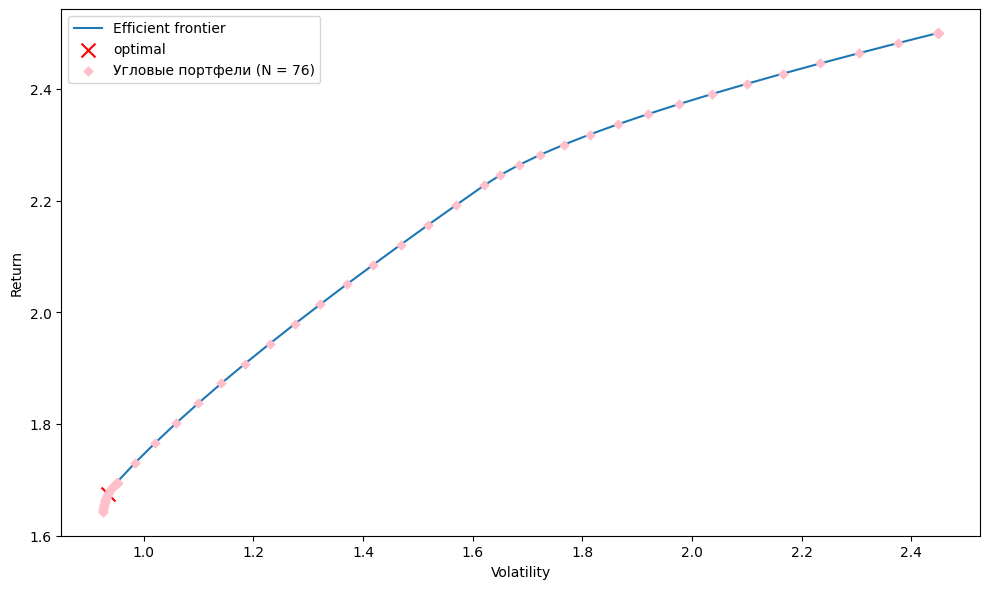

In [ ]:

fig, ax = plt.subplots(figsize=(10, 6))

# 1. Рисуем саму линию границы без точек активов
plotting.plot_efficient_frontier(cla, ax=ax, show_assets=False)

# 2. Наносим угловые портфели поверх линии
ax.scatter(
    risks,
    returns,
    marker='D',        # ромб — хорошо заметен на линии
    s=20,              # размер маркера
    c='pink',           # цвет
    zorder=5,          # чтобы точки были поверх линии
    label=f'Угловые портфели (N = {len(risks)})'
)

ax.legend()
plt.show()

### Использование фильтра угловых портфелей, оставляя только те, где меняется активное множество.

In [118]:
def filter_frontier(returns, risks, weights, tol=1e-4):
    """
    Фильтрует угловые портфели, оставляя только те, где меняется активный набор.
    
    Параметры:
    - returns: список/массив доходностей
    - risks: список/массив рисков (волатильности)
    - weights: список/массив векторов весов
    - tol: допуск (веса меньше этого значения считаются нулем)
    """
    # Приводим к numpy массивам на случай, если пришли списки
    returns = np.asarray(returns, dtype=np.float64)
    risks = np.asarray(risks, dtype=np.float64)
    weights = np.asarray(weights, dtype=np.float64)
    
    if len(weights) == 0:
        return [], [], []

    filtered_returns = []
    filtered_risks = []
    filtered_weights = []

    # Вспомогательная функция для получения маски активных активов
    # (вес строго больше tol и строго меньше 1 - tol)
    def get_active_mask(w):
        return (w > tol) & (w < 1 - tol)

    # Всегда сохраняем первую точку
    current_mask = get_active_mask(weights[0])
    filtered_returns.append(returns[0])
    filtered_risks.append(risks[0])
    filtered_weights.append(weights[0])

    # Идем по остальным точкам
    for i in range(1, len(weights)):
        new_mask = get_active_mask(weights[i])
        
        # Если набор активных активов изменился — сохраняем точку
        if not np.array_equal(current_mask, new_mask):
            filtered_returns.append(returns[i])
            filtered_risks.append(risks[i])
            filtered_weights.append(weights[i])
            current_mask = new_mask

    # Проверяем, чтобы последняя точка границы обязательно была в итоге
    if not np.array_equal(filtered_weights[-1], weights[-1]):
        filtered_returns.append(returns[-1])
        filtered_risks.append(risks[-1])
        filtered_weights.append(weights[-1])

    return np.array(filtered_returns), np.array(filtered_risks), np.array(filtered_weights)

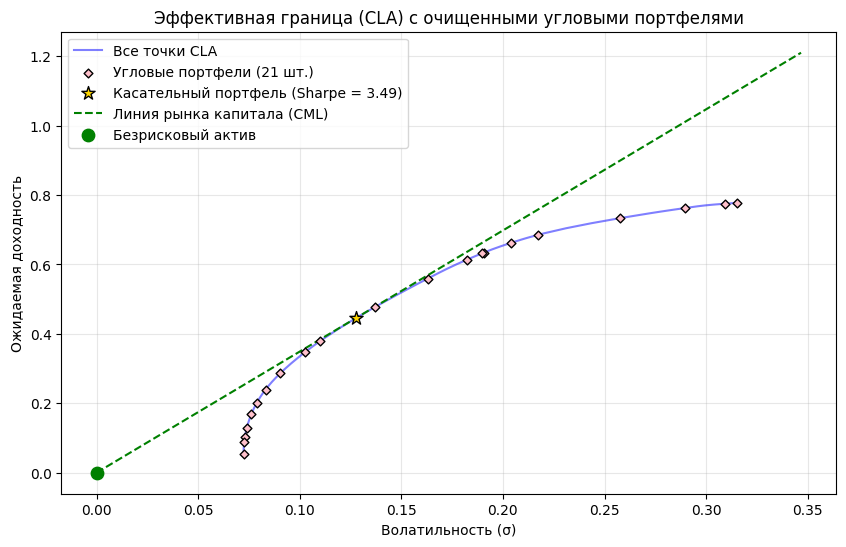

In [150]:
f_returns, f_risks, f_weights = filter_frontier(returns, risks, weights)

# 1. Получаем веса касательного портфеля
max_sharpe_weights = cla.max_sharpe()
w_opt = np.array(list(max_sharpe_weights.values()))

# 2. Считаем доходность, риск и Sharpe через встроенный метод
opt_ret, opt_vol, max_sharpe_ratio = cla.portfolio_performance(
    verbose=False  # чтобы не печатать лишний текст в консоль
)


# 3. Строим график
fig, ax = plt.subplots(figsize=(10, 6))

# Сама линия (по всем точкам, чтобы она была плавной)
ax.plot(risks, returns, 'b-', alpha=0.5, label='Все точки CLA')

# Оставляем только отфильтрованные угловые портфели
ax.scatter(f_risks, f_returns, 
           marker='D', s=20, c='pink', edgecolors='black', zorder=5, 
           label=f'Угловые портфели ({len(f_returns)} шт.)')

# Касательный портфель
ax.scatter([opt_vol], [opt_ret], 
           marker='*', s=100, c='gold', edgecolors='black', zorder=6, 
           label=f'Касательный портфель (Sharpe = {max_sharpe_ratio:.2f})')

# Линия рынка капитала (CML)
x_max = max(risks) * 1.1
x_cml = np.linspace(0, x_max, 100)
y_cml = max_sharpe_ratio * x_cml
ax.plot(x_cml, y_cml, 'g--', linewidth=1.5, label='Линия рынка капитала (CML)')

# Безрисковая ставка
ax.scatter([0], [0], marker='o', s=80, c='green', zorder=6, label='Безрисковый актив')

ax.set_xlabel('Волатильность (σ)')
ax.set_ylabel('Ожидаемая доходность')
ax.set_title('Эффективная граница (CLA) с очищенными угловыми портфелями')
ax.legend()
ax.grid(True, alpha=0.3)

plt.show()

### График от диспресии

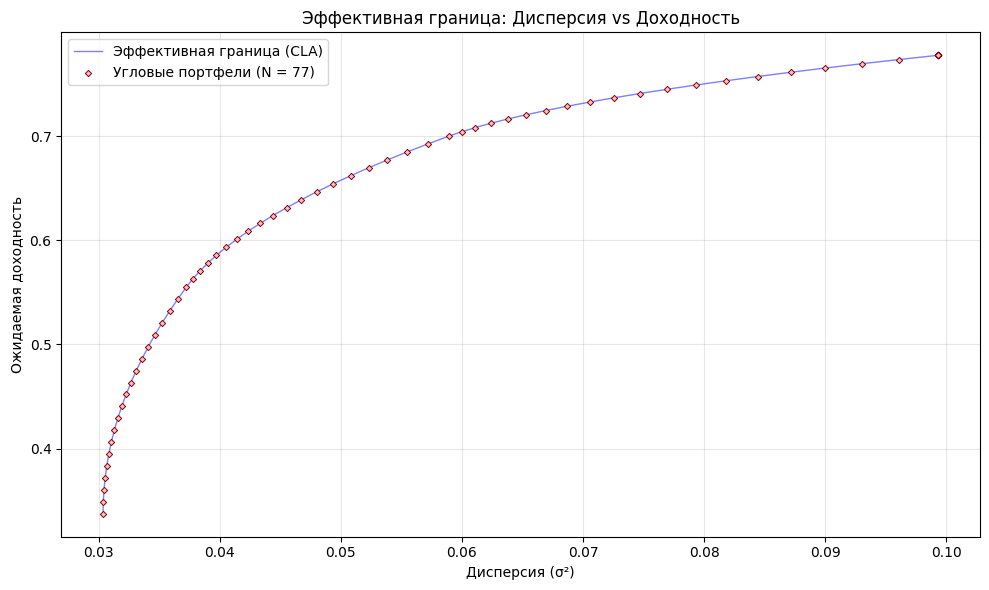

In [93]:
returns, risks, _ = cla.efficient_frontier()

# Приводим к numpy на всякий случай (метод может вернуть list)
returns_arr  = np.asarray(returns, dtype=np.float64)
risks_arr    = np.asarray(risks,   dtype=np.float64)

# Дисперсия = волатильность²
variances = risks_arr ** 2

fig, ax = plt.subplots(figsize=(10, 6))

# Линия, соединяющая turning points
ax.plot(variances, returns_arr, 'b-', linewidth=1, alpha=0.5,
        label='Эффективная граница (CLA)')

# Маркеры на самих turning points
ax.scatter(variances, returns_arr,
           marker='D',            # ромб
           s=10,                   # размер
           c='pink',
           edgecolors='darkred',
           linewidths=0.7,
           zorder=5,               # поверх линии
           label=f'Угловые портфели (N = {len(variances)})')

ax.set_xlabel('Дисперсия (σ²)')
ax.set_ylabel('Ожидаемая доходность')
ax.set_title('Эффективная граница: Дисперсия vs Доходность')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()